In [ ]:
import pandas as pd
import numpy as np
# Data: Lisbon 'listings.csv.gz' from Inside Airbnb (https://insideairbnb.com/get-the-data/)
# Save it as data/listings.csv before running.

: 

In [169]:
data = pd.read_csv('../data/listings.csv')
data.head(3)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,6499,https://www.airbnb.com/rooms/6499,20250921034206,2025-09-21,city scrape,Belém 1 Bedroom Historical Apartment,"This apartment is all about Location, next to ...","To get to the city center, tram 15 stops in f...",https://a0.muscache.com/pictures/hosting/Hosti...,14455,...,4.87,4.85,4.40,NaN,t,1,1,0,0,0.71
1,25659,https://www.airbnb.com/rooms/25659,20250921034206,2025-09-22,city scrape,Heart of Alfama - Le cœur d'Alfama (3 people),Charming apartment in Lisbon's most historic A...,"The Alfama neighborhood, is the oldest and mos...",https://a0.muscache.com/pictures/miso/Hosting-...,107347,...,4.95,4.86,4.82,56539/AL.,f,1,1,0,0,1.60
2,29396,https://www.airbnb.com/rooms/29396,20250921034206,2025-09-21,city scrape,Alfama Hill - Boutique apartment,Feel at home in the historic centre of Lisbon.,Great neighborhood in the old part of town. Am...,https://a0.muscache.com/pictures/163913/7d622c...,126415,...,4.91,4.87,4.73,28737/AL,t,1,1,0,0,2.67


In [170]:
data.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'minimum_nights_avg_ntm',
       'maximum_nights_avg_ntm', 'ca

In [ ]:
data['neighbourhood_group_cleansed'].unique()

In [ ]:
data['neighbourhood'].unique()
data['neighbourhood_cleansed'].unique()
data['neighbourhood_group_cleansed'].unique()

<StringArray>
[               'Lisboa',               'Cascais',   'Vila Franca De Xira',
                'Sintra',                'Oeiras',                 'Mafra',
         'Torres Vedras',               'Lourinh',               'Cadaval',
               'Amadora',              'Alenquer',     'Arruda Dos Vinhos',
              'Odivelas',                'Loures',              'Azambuja',
 'Sobral De Monte Agrao']
Length: 16, dtype: str

In [172]:
analysis_cols = ['id', 'price', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'amenities', 
                        'minimum_nights', 'maximum_nights', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365',
                        'number_of_reviews','number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
                        'number_of_reviews_ly', 'estimated_occupancy_l365d',
                        'estimated_revenue_l365d', 'first_review', 'last_review','review_scores_rating', 'review_scores_accuracy',
                        'review_scores_cleanliness', 'review_scores_checkin',
                        'review_scores_communication', 'review_scores_location',
                        'review_scores_value', 'reviews_per_month', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed'
]

analysis = data[analysis_cols].copy()


In [173]:
analysis.columns

Index(['id', 'price', 'room_type', 'accommodates', 'bathrooms', 'bedrooms',
       'beds', 'amenities', 'minimum_nights', 'maximum_nights',
       'has_availability', 'availability_30', 'availability_60',
       'availability_90', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
       'number_of_reviews_ly', 'estimated_occupancy_l365d',
       'estimated_revenue_l365d', 'first_review', 'last_review',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'reviews_per_month', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed'],
      dtype='str')

In [174]:
analysis['room_type'].unique()

<StringArray>
['Entire home/apt', 'Private room', 'Shared room', 'Hotel room']
Length: 4, dtype: str

In [175]:
analysis[(analysis['room_type'] == 'Private room')].describe()

,id,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,availability_30,availability_60,availability_90,...,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month
count,6.268000e+03,6268.000000,4680.000000,5189.000000,4678.000000,6268.000000,6268.000000,6268.000000,6268.000000,6268.000000,...,6268.000000,4667.000000,5128.000000,5128.000000,5128.000000,5128.000000,5128.000000,5127.000000,5128.000000,5128.000000
mean,7.540344e+17,2.027760,1.438355,1.203315,1.390765,3.093331,407.073389,10.645182,25.902680,42.623165,...,50.187779,3460.198843,4.500995,4.580419,4.523647,4.672666,4.660021,4.618379,4.456303,1.321689
std,5.720426e+17,1.004789,0.950131,1.240578,1.240890,9.319330,373.468610,10.656546,22.220908,34.530501,...,75.143482,5110.272308,0.658914,0.607087,0.670765,0.560415,0.582711,0.473112,0.655677,1.767658
min,3.334800e+04,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.010000
25%,4.257460e+07,2.000000,1.000000,1.000000,1.000000,1.000000,60.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,4.397500,4.500000,4.430000,4.650000,4.630000,4.500000,4.330000,0.230000
50%,9.274668e+17,2.000000,1.000000,1.000000,1.000000,1.000000,365.000000,8.000000,26.000000,49.000000,...,12.000000,1332.000000,4.690000,4.770000,4.750000,4.850000,4.860000,4.730000,4.630000,0.710000
75%,1.250724e+18,2.000000,2.000000,1.000000,1.000000,2.000000,365.000000,20.000000,47.000000,76.000000,...,66.000000,4872.000000,4.910000,4.940000,4.950000,5.000000,5.000000,4.910000,4.840000,1.770000
max,1.513534e+18,16.000000,14.000000,43.000000,27.000000,365.000000,2125.000000,30.000000,60.000000,90.000000,...,255.000000,71655.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,29.720000


Data Cleaning

In [176]:
analysis.isnull().sum()

id                                  0
price                            3579
room_type                           0
accommodates                        0
bathrooms                        3536
bedrooms                         1185
beds                             3562
amenities                           0
minimum_nights                      0
maximum_nights                      0
has_availability                  722
availability_30                     0
availability_60                     0
availability_90                     0
availability_365                    0
number_of_reviews                   0
number_of_reviews_ltm               0
number_of_reviews_l30d              0
availability_eoy                    0
number_of_reviews_ly                0
estimated_occupancy_l365d           0
estimated_revenue_l365d          3579
first_review                     3194
last_review                      3194
review_scores_rating             3194
review_scores_accuracy           3194
review_score

In [177]:
analysis.dtypes

id                                int64
price                               str
room_type                           str
accommodates                      int64
bathrooms                       float64
bedrooms                        float64
beds                            float64
amenities                           str
minimum_nights                    int64
maximum_nights                    int64
has_availability                    str
availability_30                   int64
availability_60                   int64
availability_90                   int64
availability_365                  int64
number_of_reviews                 int64
number_of_reviews_ltm             int64
number_of_reviews_l30d            int64
availability_eoy                  int64
number_of_reviews_ly              int64
estimated_occupancy_l365d         int64
estimated_revenue_l365d         float64
first_review                        str
last_review                         str
review_scores_rating            float64


In [178]:
analysis.head()

,id,price,room_type,accommodates,bathrooms,bedrooms,beds,amenities,minimum_nights,maximum_nights,...,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed
0,6499,$87.00,Entire home/apt,3,1.0,1.0,3.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si...",3,365,...,4.47,4.45,4.84,4.87,4.85,4.40,0.71,"Lisbon, Portugal",Belm,Lisboa
1,25659,$92.00,Entire home/apt,3,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si...",2,14,...,4.88,4.87,4.90,4.95,4.86,4.82,1.60,"Lisbon, Portugal",Santa Maria Maior,Lisboa
2,29396,$77.00,Entire home/apt,4,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Waterfront"", ...",3,1125,...,4.81,4.75,4.86,4.91,4.87,4.73,2.67,"Lisbon, Portugal",Santa Maria Maior,Lisboa
3,29720,"$1,250.00",Entire home/apt,16,8.0,9.0,13.0,"[""Dishes and silverware"", ""Host greets you"", ""...",2,1125,...,4.91,4.87,4.96,4.96,4.87,4.70,0.90,"Lisbon, Portugal",Estrela,Lisboa
4,29915,$96.00,Entire home/apt,3,1.0,1.0,2.0,"[""Microwave"", ""HDTV with standard cable"", ""Coo...",6,365,...,4.71,4.74,4.77,4.63,4.61,4.54,0.33,"Lisbon, Portugal",Avenidas Novas,Lisboa


In [179]:
analysis['price'] = analysis['price'].str.replace('$', '', regex = False)
analysis['price'] = analysis['price'].str.replace(',', '', regex = False)
analysis['price'] = pd.to_numeric(analysis['price'], errors = 'coerce')
analysis.head()

,id,price,room_type,accommodates,bathrooms,bedrooms,beds,amenities,minimum_nights,maximum_nights,...,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed
0,6499,87.0,Entire home/apt,3,1.0,1.0,3.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si...",3,365,...,4.47,4.45,4.84,4.87,4.85,4.40,0.71,"Lisbon, Portugal",Belm,Lisboa
1,25659,92.0,Entire home/apt,3,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si...",2,14,...,4.88,4.87,4.90,4.95,4.86,4.82,1.60,"Lisbon, Portugal",Santa Maria Maior,Lisboa
2,29396,77.0,Entire home/apt,4,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Waterfront"", ...",3,1125,...,4.81,4.75,4.86,4.91,4.87,4.73,2.67,"Lisbon, Portugal",Santa Maria Maior,Lisboa
3,29720,1250.0,Entire home/apt,16,8.0,9.0,13.0,"[""Dishes and silverware"", ""Host greets you"", ""...",2,1125,...,4.91,4.87,4.96,4.96,4.87,4.70,0.90,"Lisbon, Portugal",Estrela,Lisboa
4,29915,96.0,Entire home/apt,3,1.0,1.0,2.0,"[""Microwave"", ""HDTV with standard cable"", ""Coo...",6,365,...,4.71,4.74,4.77,4.63,4.61,4.54,0.33,"Lisbon, Portugal",Avenidas Novas,Lisboa


In [180]:
analysis.dtypes

id                                int64
price                           float64
room_type                           str
accommodates                      int64
bathrooms                       float64
bedrooms                        float64
beds                            float64
amenities                           str
minimum_nights                    int64
maximum_nights                    int64
has_availability                    str
availability_30                   int64
availability_60                   int64
availability_90                   int64
availability_365                  int64
number_of_reviews                 int64
number_of_reviews_ltm             int64
number_of_reviews_l30d            int64
availability_eoy                  int64
number_of_reviews_ly              int64
estimated_occupancy_l365d         int64
estimated_revenue_l365d         float64
first_review                        str
last_review                         str
review_scores_rating            float64


In [181]:
analysis.isnull().sum()

id                                  0
price                            3579
room_type                           0
accommodates                        0
bathrooms                        3536
bedrooms                         1185
beds                             3562
amenities                           0
minimum_nights                      0
maximum_nights                      0
has_availability                  722
availability_30                     0
availability_60                     0
availability_90                     0
availability_365                    0
number_of_reviews                   0
number_of_reviews_ltm               0
number_of_reviews_l30d              0
availability_eoy                    0
number_of_reviews_ly                0
estimated_occupancy_l365d           0
estimated_revenue_l365d          3579
first_review                     3194
last_review                      3194
review_scores_rating             3194
review_scores_accuracy           3194
review_score

In [182]:
analysis.isnull().mean()

id                              0.000000
price                           0.140634
room_type                       0.000000
accommodates                    0.000000
bathrooms                       0.138945
bedrooms                        0.046564
beds                            0.139966
amenities                       0.000000
minimum_nights                  0.000000
maximum_nights                  0.000000
has_availability                0.028370
availability_30                 0.000000
availability_60                 0.000000
availability_90                 0.000000
availability_365                0.000000
number_of_reviews               0.000000
number_of_reviews_ltm           0.000000
number_of_reviews_l30d          0.000000
availability_eoy                0.000000
number_of_reviews_ly            0.000000
estimated_occupancy_l365d       0.000000
estimated_revenue_l365d         0.140634
first_review                    0.125506
last_review                     0.125506
review_scores_ra

In [183]:
analysis['accommodates'] = pd.to_numeric(analysis['accommodates'], errors='coerce')

The percentage of null in 'price' is too high(14%) which can not be just removed. Therefore, that column will be filled in median price group by the room type.

In [184]:
analysis['price'] = analysis.groupby('room_type')['price'].transform(lambda x: x.fillna(x.median()))


In [185]:
analysis['price'].isnull().sum()

np.int64(0)

In [186]:
analysis.groupby('room_type')[['bathrooms', 'bedrooms', 'beds']].apply(lambda x: x.isnull().mean())

,bathrooms,bedrooms,beds
room_type,,,
Entire home/apt,0.098544,0.003825,0.098916
Hotel room,0.377990,0.000000,0.454545
Private room,0.253350,0.172144,0.253669
Shared room,0.094595,0.229730,0.101351


In [187]:
analysis.groupby('room_type')[['bathrooms', 'bedrooms', 'beds']].apply(lambda x: x.median())

,bathrooms,bedrooms,beds
room_type,,,
Entire home/apt,1.0,2.0,2.0
Hotel room,1.0,1.0,1.0
Private room,1.0,1.0,1.0
Shared room,1.5,1.0,3.0


In [188]:
for col in ['bathrooms', 'bedrooms', 'beds']:
    analysis[col] = analysis.groupby(['room_type', 'accommodates'])[col].transform(
        lambda x: x.fillna(x.median())
    )

for col in ['bathrooms', 'bedrooms', 'beds']:
    analysis[col] = analysis.groupby('room_type')[col].transform(
        lambda x: x.fillna(x.median())
    )

In [189]:
analysis.isnull().sum()

id                                  0
price                               0
room_type                           0
accommodates                        0
bathrooms                           0
bedrooms                            0
beds                                0
amenities                           0
minimum_nights                      0
maximum_nights                      0
has_availability                  722
availability_30                     0
availability_60                     0
availability_90                     0
availability_365                    0
number_of_reviews                   0
number_of_reviews_ltm               0
number_of_reviews_l30d              0
availability_eoy                    0
number_of_reviews_ly                0
estimated_occupancy_l365d           0
estimated_revenue_l365d          3579
first_review                     3194
last_review                      3194
review_scores_rating             3194
review_scores_accuracy           3194
review_score

In [190]:
repr(analysis.loc[9687, 'room_type'])

"'Private room'"

In [191]:
analysis.describe()

,id,price,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,availability_30,availability_60,...,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month
count,2.544900e+04,25449.000000,25449.000000,25449.000000,25449.000000,25449.000000,25449.000000,25449.000000,25449.000000,25449.000000,...,25449.000000,2.187000e+04,22255.000000,22255.000000,22255.000000,22255.000000,22255.000000,22254.000000,22255.000000,22255.000000
mean,6.052322e+17,226.643306,3.785846,1.415969,1.670321,2.357421,4.719989,475.333805,9.752250,26.479390,...,79.009352,1.423886e+04,4.638029,4.700344,4.665163,4.760347,4.766672,4.689312,4.550036,1.566873
std,5.914290e+17,1681.535633,2.369270,0.895539,1.245962,1.980893,16.810821,484.634591,9.400526,19.386102,...,88.834445,1.899106e+05,0.473255,0.439956,0.473011,0.399408,0.420863,0.383832,0.487553,1.551474
min,6.499000e+03,9.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.010000
25%,2.635673e+07,70.000000,2.000000,1.000000,1.000000,1.000000,1.000000,65.000000,1.000000,8.000000,...,0.000000,7.270000e+02,4.540000,4.650000,4.580000,4.730000,4.740000,4.590000,4.460000,0.390000
50%,6.598273e+17,112.000000,4.000000,1.000000,1.000000,2.000000,2.000000,365.000000,7.000000,27.000000,...,40.000000,5.616000e+03,4.760000,4.820000,4.800000,4.870000,4.890000,4.790000,4.670000,1.090000
75%,1.182779e+18,155.000000,4.000000,2.000000,2.000000,3.000000,3.000000,1125.000000,16.000000,42.000000,...,138.000000,1.688100e+04,4.910000,4.930000,4.930000,4.960000,4.980000,4.920000,4.810000,2.320000
max,1.513766e+18,86733.000000,16.000000,26.000000,43.000000,40.000000,1000.000000,36180.000000,30.000000,60.000000,...,255.000000,2.211692e+07,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,29.720000


In [192]:
analysis.groupby('room_type')[['bathrooms', 'bedrooms', 'beds']].apply(lambda x: x.median())

,bathrooms,bedrooms,beds
room_type,,,
Entire home/apt,1.0,2.0,2.0
Hotel room,1.0,1.0,1.0
Private room,1.0,1.0,1.0
Shared room,1.5,1.0,3.0


Build a main analytic dataframe: analysis_couple

In [193]:
analysis.columns

Index(['id', 'price', 'room_type', 'accommodates', 'bathrooms', 'bedrooms',
       'beds', 'amenities', 'minimum_nights', 'maximum_nights',
       'has_availability', 'availability_30', 'availability_60',
       'availability_90', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
       'number_of_reviews_ly', 'estimated_occupancy_l365d',
       'estimated_revenue_l365d', 'first_review', 'last_review',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'reviews_per_month', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed'],
      dtype='str')

In [194]:
analysis_lisbon = analysis[analysis['neighbourhood_group_cleansed'] == 'Lisboa'].copy()

In [195]:
analysis_couple = analysis_lisbon[(analysis_lisbon['accommodates'] >= 2) &
         (analysis_lisbon['bedrooms'] >= 1) &
         (analysis_lisbon['beds'] >= 1) &
         (analysis_lisbon['bathrooms'] >= 1)
]


In [196]:
analysis_couple.describe()

,id,price,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,availability_30,availability_60,...,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month
count,1.532200e+04,15322.000000,15322.000000,15322.000000,15322.000000,15322.000000,15322.000000,15322.000000,15322.000000,15322.000000,...,15322.000000,1.334600e+04,13588.000000,13588.000000,13588.000000,13588.000000,13588.000000,13588.000000,13588.000000,13588.000000
mean,5.774213e+17,171.703433,3.746312,1.365194,1.642540,2.251403,4.920115,490.290758,8.256298,24.272941,...,94.862877,1.818778e+04,4.609143,4.683259,4.646086,4.741743,4.748432,4.691838,4.524750,1.822541
std,5.957201e+17,985.102517,2.074755,0.787205,1.069517,1.756757,15.821054,434.273169,8.313942,17.768836,...,94.837663,2.425416e+05,0.480621,0.443654,0.479526,0.404975,0.430854,0.382000,0.491102,1.603839
min,6.499000e+03,9.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.010000
25%,2.440614e+07,80.000000,2.000000,1.000000,1.000000,1.000000,1.000000,90.000000,1.000000,9.000000,...,6.000000,1.308000e+03,4.510000,4.630000,4.570000,4.700000,4.710000,4.600000,4.440000,0.550000
50%,5.875666e+17,120.000000,4.000000,1.000000,1.000000,2.000000,2.000000,365.000000,6.000000,24.000000,...,60.000000,8.544000e+03,4.730000,4.800000,4.780000,4.850000,4.870000,4.800000,4.640000,1.460000
75%,1.181595e+18,160.000000,4.000000,2.000000,2.000000,3.000000,3.000000,1125.000000,13.000000,37.000000,...,180.000000,2.167500e+04,4.880000,4.910000,4.910000,4.940000,4.960000,4.910000,4.790000,2.720000
max,1.513685e+18,86733.000000,16.000000,26.000000,25.000000,38.000000,730.000000,2125.000000,30.000000,60.000000,...,255.000000,2.211692e+07,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,29.720000


Analysis the room type

In [197]:
analysis['room_type'].unique()

<StringArray>
['Entire home/apt', 'Private room', 'Shared room', 'Hotel room']
Length: 4, dtype: str

In [198]:
analysis_couple = analysis_couple[analysis_couple['room_type'] != 'Shared room']

In [199]:
analysis_couple['room_type'].unique()

<StringArray>
['Entire home/apt', 'Private room', 'Hotel room']
Length: 3, dtype: str

Availbility

In [200]:
availability_couple = analysis_couple.copy()
availability_couple[['price','room_type', 'accommodates','bathrooms',
            'bedrooms', 'beds',
            'amenities' ,'minimum_nights',
            'maximum_nights','availability_30', 'availability_60','availability_90',
            'availability_365']].head()

,price,room_type,accommodates,bathrooms,bedrooms,beds,amenities,minimum_nights,maximum_nights,availability_30,availability_60,availability_90,availability_365
0,87.0,Entire home/apt,3,1.0,1.0,3.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si...",3,365,5,11,29,283
1,92.0,Entire home/apt,3,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si...",2,14,10,28,58,324
2,77.0,Entire home/apt,4,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Waterfront"", ...",3,1125,3,11,41,287
3,1250.0,Entire home/apt,16,8.0,9.0,13.0,"[""Dishes and silverware"", ""Host greets you"", ""...",2,1125,9,34,64,308
4,96.0,Entire home/apt,3,1.0,1.0,2.0,"[""Microwave"", ""HDTV with standard cable"", ""Coo...",6,365,4,19,47,68


In [201]:
availability_couple.describe()

,id,price,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,availability_30,availability_60,...,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month
count,1.529700e+04,15297.000000,15297.000000,15297.000000,15297.000000,15297.000000,15297.000000,15297.000000,15297.000000,15297.000000,...,15297.000000,1.332100e+04,13570.000000,13570.000000,13570.000000,13570.000000,13570.000000,13570.000000,13570.000000,13570.000000
mean,5.764178e+17,171.875989,3.744917,1.364091,1.643133,2.248415,4.924495,490.261162,8.243185,24.254364,...,94.933386,1.821758e+04,4.609376,4.683537,4.646144,4.741965,4.748754,4.691914,4.524783,1.820804
std,5.954627e+17,985.892340,2.071339,0.786110,1.068853,1.750523,15.831945,434.381368,8.303795,17.757883,...,94.838732,2.427681e+05,0.480060,0.442758,0.479244,0.404398,0.430065,0.381417,0.490878,1.596942
min,6.499000e+03,18.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.010000
25%,2.436733e+07,80.000000,2.000000,1.000000,1.000000,1.000000,1.000000,90.000000,1.000000,9.000000,...,6.000000,1.320000e+03,4.510000,4.630000,4.570000,4.700000,4.710000,4.600000,4.440000,0.550000
50%,5.859959e+17,120.000000,4.000000,1.000000,1.000000,2.000000,2.000000,365.000000,6.000000,24.000000,...,60.000000,8.568000e+03,4.730000,4.800000,4.780000,4.850000,4.870000,4.800000,4.640000,1.465000
75%,1.181160e+18,160.000000,4.000000,2.000000,2.000000,3.000000,3.000000,1125.000000,13.000000,37.000000,...,180.000000,2.167500e+04,4.880000,4.910000,4.910000,4.940000,4.960000,4.910000,4.790000,2.720000
max,1.513685e+18,86733.000000,16.000000,26.000000,25.000000,38.000000,730.000000,2125.000000,30.000000,60.000000,...,255.000000,2.211692e+07,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,29.720000


availabilty within 30 days might have gap.
But it means that the demand and supply almostly stricks a balance.

short-term bookable availability is limited

Reasonable price

In [202]:
price_couple= analysis_couple.copy()
price_couple[['price','room_type', 'accommodates','bathrooms',
            'bedrooms', 'beds','amenities'
            ]].head()

,price,room_type,accommodates,bathrooms,bedrooms,beds,amenities
0,87.0,Entire home/apt,3,1.0,1.0,3.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si..."
1,92.0,Entire home/apt,3,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Dishes and si..."
2,77.0,Entire home/apt,4,1.0,1.0,1.0,"[""Microwave"", ""Cooking basics"", ""Waterfront"", ..."
3,1250.0,Entire home/apt,16,8.0,9.0,13.0,"[""Dishes and silverware"", ""Host greets you"", ""..."
4,96.0,Entire home/apt,3,1.0,1.0,2.0,"[""Microwave"", ""HDTV with standard cable"", ""Coo..."


In [203]:
price_couple.groupby('room_type')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,12112.0,194.611460,1105.110500,23.0,98.0,125.0,172.0,86733.0
Hotel room,118.0,206.500000,155.544659,47.0,152.0,180.5,180.5,850.0
Private room,3067.0,80.758396,117.006163,18.0,49.0,57.0,72.0,1421.0


In [204]:
price_couple['accommodates'].dtype

dtype('int64')

In [205]:
price_couple[price_couple['accommodates'] == 2].groupby('room_type')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,3062.0,202.727302,2043.504357,30.0,83.00,106.0,125.0,86733.0
Hotel room,87.0,216.511494,177.344429,47.0,157.75,180.5,180.5,850.0
Private room,2700.0,77.598889,110.622990,18.0,48.00,57.0,69.0,1421.0


So expensive! private room is relatively cheap.
The market offers low-cost options mainly through private rooms, but affordable options with greater privacy and comfort for retired couples appear more limited.

Location near supermarket and convenient transportation system


amenties especially kitchen tool, laundry, wifi

Review with high score(at least higher than average) and recently higher number of reviews

In [206]:
review_couple= analysis_couple.copy()
review_couple[['number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d',
                        'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'estimated_revenue_l365d',
                        'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy',
                        'review_scores_cleanliness', 'review_scores_checkin',
                        'review_scores_communication', 'review_scores_location',
                        'review_scores_value', 'reviews_per_month']].head()

,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month
0,95,19,1,30,17,114,9918.0,2014-09-02,2025-09-03,4.52,4.47,4.45,4.84,4.87,4.85,4.40,0.71
1,223,10,2,68,14,60,5520.0,2014-04-24,2025-09-18,4.82,4.88,4.87,4.90,4.95,4.86,4.82,1.60
2,433,32,2,50,23,192,14784.0,2012-05-22,2025-09-11,4.77,4.81,4.75,4.86,4.91,4.87,4.73,2.67
3,161,27,5,76,22,162,202500.0,2011-01-05,2025-09-14,4.94,4.91,4.87,4.96,4.96,4.87,4.70,0.90
4,61,0,0,47,2,0,0.0,2010-07-24,2024-05-20,4.57,4.71,4.74,4.77,4.63,4.61,4.54,0.33


number_of_reviews_l30d is near zero
number_of_reviews_ltm provides more quality to refer

Lifeime revies indicate historical popularity, but they may overstate the attractiveness of older listings.
For understanding current market demend, recent reviews activity over the last 12 months is more informative.

In [207]:
review_couple[['number_of_reviews', 'number_of_reviews_ltm', 'review_scores_cleanliness', 
               'review_scores_communication', 'review_scores_location']].describe()

,number_of_reviews,number_of_reviews_ltm,review_scores_cleanliness,review_scores_communication,review_scores_location
count,15297.000000,15297.000000,13570.000000,13570.000000,13570.000000
mean,88.076028,16.713996,4.646144,4.748754,4.691914
std,123.349426,19.972248,0.479244,0.430065,0.381417
min,0.000000,0.000000,0.000000,1.000000,1.000000
25%,4.000000,1.000000,4.570000,4.710000,4.600000
50%,34.000000,9.000000,4.780000,4.870000,4.800000
75%,124.000000,28.000000,4.910000,4.960000,4.910000
max,1787.000000,329.000000,5.000000,5.000000,5.000000


In [208]:
review_couple['recent_review_ratio'] = np.where(
    review_couple['number_of_reviews'] > 0,
    review_couple['number_of_reviews_ltm'] / review_couple['number_of_reviews'],
    np.nan
)

review_couple['recent_review_pct'] = review_couple['recent_review_ratio']*100
review_couple['recent_review_pct'].head()

0    20.000000
1     4.484305
2     7.390300
3    16.770186
4     0.000000
Name: recent_review_pct, dtype: float64

In [209]:
high_review = review_couple[
    (review_couple['review_scores_cleanliness'] >= review_couple['review_scores_cleanliness'].median()) &
    (review_couple['review_scores_communication'] >= review_couple['review_scores_communication'].median()) &
    (review_couple['review_scores_location'] >= review_couple['review_scores_location'].median())
]

high_review[['number_of_reviews', 'number_of_reviews_ltm', 'recent_review_pct']].describe()

,number_of_reviews,number_of_reviews_ltm,recent_review_pct
count,3548.000000,3548.000000,3548.000000
mean,130.243517,23.142616,37.299677
std,153.473563,23.143427,36.860612
min,1.000000,0.000000,0.000000
25%,7.000000,2.000000,10.079804
50%,74.000000,17.000000,20.000000
75%,205.000000,40.000000,66.166667
max,1257.000000,329.000000,100.000000


Key finding: The listing represnets that most of properties with higher quality has reasonable number of recent reviews. still active
 

Combine quality and activity

A. High score + high recent reviews
These are likely the strongest market performers.
They may represent what the market values most.

B. High score + low recent reviews
These may be good-quality but not very visible, not available or not competitively priced.

C. Low score + high recent reviews
the listing may not really good but is still attractive since good location or low price.

D. Low score + low recent reviews
These are close to be abandoned with the lowest competitiveness.

Quality vs room type

In [210]:
high_review.groupby(high_review['room_type'])[['room_type', 'price']].describe()

price                                                       \
                  count        mean          std    min    25%    50%    75%   
room_type                                                                      
Entire home/apt  3064.0  239.104765  1992.858281   28.0  110.0  139.0  199.0   
Hotel room         15.0  206.700000    56.809142  122.0  180.5  180.5  252.0   
Private room      469.0   85.686567    72.199287   26.0   55.0   59.0  100.0   

                          
                     max  
room_type                 
Entire home/apt  86733.0  
Hotel room         327.0  
Private room      1080.0

Key findings: Among the data with better quality room, the price of hotel room is generally higher than entire home and private room, but the price is more stable with lower standard deviation. The price of private rooms are almost half of the price of entire home and hotel home, providing a cost-effective choice for middele-class retired couple.
In terms of the count column, the figure can be compared with the available room data to analysis the market supply and demand. 
However, the total number of hotel room is siginificant low. Compared with that, the private room is enough, however, the entire apartment offers a lot. Travelers might meet the stock in certain type of room.


Quality vs Availability

In [211]:
high_review[['minimum_nights', 'maximum_nights', 'availability_30',
       'availability_60', 'availability_90', 'availability_365']].head()

,minimum_nights,maximum_nights,availability_30,availability_60,availability_90,availability_365
1,2,14,10,28,58,324
3,2,1125,9,34,64,308
32,3,1125,4,20,36,114
33,3,365,5,19,30,303
38,1,3,4,24,43,223


Short-notice travel

In [212]:
feasible_30 = high_review[(high_review['minimum_nights'] < high_review['availability_30'])
            ]
feasible_30[['minimum_nights', 'availability_30']]

,minimum_nights,availability_30
1,2,10
3,2,9
32,3,4
33,3,5
38,1,4
...,...,...
25377,3,11
25390,3,17
25398,1,27
25418,2,15


In [213]:
feasible_30.groupby('room_type')['room_type'].describe()

,count,unique,top,freq
room_type,,,,
Entire home/apt,1876,1,Entire home/apt,1876
Hotel room,9,1,Hotel room,9
Private room,307,1,Private room,307


Planned travel

In [214]:
feasible_90 = high_review[(high_review['minimum_nights'] < high_review['availability_90'])]

feasible_90[['minimum_nights', 'availability_90']]

,minimum_nights,availability_90
1,2,58
3,2,64
32,3,36
33,3,30
38,1,43
...,...,...
25377,3,62
25390,3,77
25398,1,87
25418,2,75


In [215]:
feasible_90.groupby('room_type')['room_type'].describe()

,count,unique,top,freq
room_type,,,,
Entire home/apt,2655,1,Entire home/apt,2655
Hotel room,10,1,Hotel room,10
Private room,368,1,Private room,368


In [216]:
feasible_365 = high_review[(high_review['minimum_nights'] < high_review['availability_365'])]

feasible_365[['minimum_nights', 'availability_365']]

,minimum_nights,availability_365
1,2,324
3,2,308
32,3,114
33,3,303
38,1,223
...,...,...
25377,3,242
25390,3,352
25398,1,362
25418,2,350


In [217]:
feasible_365.groupby('room_type')['room_type'].describe()

,count,unique,top,freq
room_type,,,,
Entire home/apt,2845,1,Entire home/apt,2845
Hotel room,11,1,Hotel room,11
Private room,393,1,Private room,393


Entire room provides a lot choices if reired couple plan the trip in advance,
In Potual, there is less hotel.


Location

In [218]:
location_analysis = analysis_couple.copy()
location_analysis[['room_type', 'review_scores_location', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed']].head()

,room_type,review_scores_location,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed
0,Entire home/apt,4.85,"Lisbon, Portugal",Belm,Lisboa
1,Entire home/apt,4.86,"Lisbon, Portugal",Santa Maria Maior,Lisboa
2,Entire home/apt,4.87,"Lisbon, Portugal",Santa Maria Maior,Lisboa
3,Entire home/apt,4.87,"Lisbon, Portugal",Estrela,Lisboa
4,Entire home/apt,4.61,"Lisbon, Portugal",Avenidas Novas,Lisboa


In [219]:
location_analysis['neighbourhood'].unique()

<StringArray>
[                              'Lisbon, Portugal',
                                              nan,
                       'Lisbon, Lisboa, Portugal',
              'Lisbon, Lisbon District, Portugal',
                               'Lisboa, Portugal',
                  'Lisbon, Estremadura, Portugal',
                         'Bica, Lisbon, Portugal',
                      ' Lisbon, Lisboa, Portugal',
                           'Lisbon, Li, Portugal',
                       'Lisbon, Mescês, Portugal',
                     'Lisbon, Lisbonne, Portugal',
               'Lisbon, Santos-o-velho, Portugal',
                     'Lisbon, (Alfama), Portugal',
           'Lisbon, Distrito de Lisboa, Portugal',
                       'Lisbon, Alfama, Portugal',
               'Lisbon, Santa Apolónia, Portugal',
                       'Lisbon, lisboa, Portugal',
              'Lisbon, Bairro da Graça, Portugal',
           'Praça Martim Moniz, Lisboa, Portugal',
                 

In [220]:
location_analysis['neighbourhood_group_cleansed'].unique()

<StringArray>
['Lisboa']
Length: 1, dtype: str

In [221]:
location_analysis['neighbourhood_cleansed'].unique()

<StringArray>
[                  'Belm',      'Santa Maria Maior',                'Estrela',
         'Avenidas Novas',                 'Lumiar',            'Misericrdia',
              'Campolide',             'So Vicente',       'Campo de Ourique',
                'Arroios',           'Santo Antnio',               'Alcntara',
        'Parque das Naes',         'Penha de Frana',                  'Ajuda',
                'Carnide',                'Areeiro',               'Alvalade',
                'Olivais',                  'Beato',                'Marvila',
 'So Domingos de Benfica',                'Benfica',            'Santa Clara']
Length: 24, dtype: str

In [222]:
high_review.groupby(['neighbourhood_cleansed', 'room_type'])[['price', 'availability_30', 'review_scores_location']].describe()


price                                  \
                                        count        mean          std    min   
neighbourhood_cleansed room_type                                                
Ajuda                  Entire home/apt   32.0  122.968750    69.546682   55.0   
                       Private room       5.0   60.400000     9.370165   50.0   
Alcntara               Entire home/apt   33.0  155.939394    94.024578   49.0   
                       Private room       5.0   76.400000    29.236963   33.0   
Alvalade               Entire home/apt   35.0  171.085714   123.511936   60.0   
                       Private room       6.0   66.833333    20.672849   45.0   
Areeiro                Entire home/apt   28.0  154.785714   142.670394   55.0   
                       Private room      28.0   81.142857    31.964928   27.0   
Arroios                Entire home/apt  135.0  221.200000   804.149804   42.0   
                       Private room      71.0   64.098592    31.189813   32.0   
Avenidas Novas         Entire home/apt  111.0  185.486486   116.586204   57.0   
                       Hotel room         2.0  128.500000     9.192388  122.0   
                       Private room      36.0   65.361111    23.281081   30.0   
Beato                  Private room       1.0   57.000000          NaN   57.0   
Belm                   Entire home/apt   68.0  118.735294    77.571848   34.0   
                       Private room      12.0   83.083333    41.482654   42.0   
Benfica                Entire home/apt    5.0  214.000000   246.177781   69.0   
                       Private room       3.0   44.000000    14.106736   29.0   
Campo de Ourique       Entire home/apt   83.0  138.734940    63.998682   63.0   
                       Private room      16.0   59.000000    13.226237   37.0   
Campolide              Entire home/apt   17.0  147.352941    74.262155   76.0   
                       Private room       5.0   99.200000    49.499495   57.0   
Carnide                Entire home/apt    7.0  118.000000    29.844039   60.0   
Estrela                Entire home/apt  157.0  172.554140   146.903745   60.0   
                       Private room      21.0   87.142857    59.561133   34.0   
Lumiar                 Entire home/apt   17.0  127.529412    34.749312   78.0   
                       Private room       6.0   51.500000    14.363147   34.0   
Marvila                Entire home/apt    9.0  321.888889   324.030648  121.0   
                       Private room       2.0   41.000000     5.656854   37.0   
Misericrdia            Entire home/apt  697.0  175.919656   153.510771   44.0   
                       Hotel room         9.0  230.222222    52.417263  180.5   
                       Private room      70.0  104.300000    77.424737   33.0   
Olivais                Entire home/apt   21.0  136.714286    56.103603   58.0   
                       Private room      11.0   57.818182    13.444837   34.0   
Parque das Naes        Entire home/apt   70.0  143.342857    75.345366   40.0   
                       Private room       3.0   57.333333    10.503968   47.0   
Penha de Frana         Entire home/apt   25.0  118.560000    40.694062   60.0   
                       Private room      18.0   89.722222    79.191358   37.0   
Santa Clara            Private room       2.0   39.500000     3.535534   37.0   
Santa Maria Maior      Entire home/apt  926.0  226.673866   540.221714   28.0   
                       Hotel room         3.0  175.833333    28.785123  145.0   
                       Private room      67.0  121.044776    77.154790   26.0   
Santo Antnio           Entire home/apt  335.0  661.841791  5921.138775   50.0   
                       Hotel room         1.0  244.000000          NaN  244.0   
                       Private room      43.0   88.116279    41.290613   49.0   
So Domingos de Benfica Entire home/apt   12.0  153.000000    69.502126   59.0   
                       Private room       4.0   59.000000     4.082483 

Key finding: Based on thesee information, I found that some cities with higher count but low availability over 30 days. It means there is a demand gap. Moreover, hotel room only provided by certain area with higher total properties, indicating hotel room only build in popular area. In terms of availability, the percentage of availability belongs to private room is higher, showing that entire room is more attractive in Lisbon.

In [223]:
high_loc_review = review_couple[
    (review_couple['review_scores_location'] >= review_couple['review_scores_location'].median())
]

high_loc_review.groupby(['neighbourhood_cleansed', 'room_type'])[['price', 'availability_30', 'review_scores_location']].describe()

price                           \
                                         count        mean          std   
neighbourhood_cleansed room_type                                          
Ajuda                  Entire home/apt    46.0  115.521739    60.244590   
                       Private room        7.0   57.714286     8.994707   
Alcntara               Entire home/apt    51.0  154.803922    97.043087   
                       Private room       10.0   64.700000    23.772299   
Alvalade               Entire home/apt    54.0  154.648148   104.142891   
                       Hotel room          1.0  180.500000          NaN   
                       Private room       12.0   58.666667    19.717705   
Areeiro                Entire home/apt    51.0  137.333333   111.869865   
                       Private room       55.0   69.218182    26.285957   
Arroios                Entire home/apt   221.0  268.904977  1052.272577   
                       Hotel room          1.0  180.500000          NaN   
                       Private room      120.0   63.358333    27.761226   
Avenidas Novas         Entire home/apt   190.0  184.184211   209.564686   
                       Hotel room          4.0  121.625000    54.527325   
                       Private room       88.0   62.022727    21.625856   
Beato                  Entire home/apt     2.0  166.000000    57.982756   
                       Private room        1.0   57.000000          NaN   
Belm                   Entire home/apt   111.0  144.144144   141.577980   
                       Private room       19.0   75.421053    36.020543   
Benfica                Entire home/apt    14.0  149.214286   147.606639   
                       Private room        6.0   48.666667    10.595597   
Campo de Ourique       Entire home/apt   116.0  136.689655    65.970008   
                       Private room       19.0   58.368421    12.221159   
Campolide              Entire home/apt    22.0  140.727273    67.246655   
                       Private room        6.0   92.166667    47.507543   
Carnide                Entire home/apt    10.0  113.400000    27.224172   
                       Private room        3.0   39.000000     6.557439   
Estrela                Entire home/apt   274.0  159.379562   126.179657   
                       Private room       33.0   80.545455    51.182938   
Lumiar                 Entire home/apt    23.0  122.913043    36.691482   
                       Private room        7.0   51.000000    13.178265   
Marvila                Entire home/apt    15.0  238.200000   267.425610   
                       Private room        2.0   41.000000     5.656854   
Misericrdia            Entire home/apt  1387.0  181.658255   394.982125   
                       Hotel room         17.0  247.147059    70.820805   
                       Private room      198.0   83.878788    60.965626   
Olivais                Entire home/apt    25.0  136.680000    57.296539   
                       Private room       15.0   62.400000    23.987497   
Parque das Naes        Entire home/apt   136.0  157.595588    74.529276   
                       Private room        5.0   57.600000    15.978110   
Penha de Frana         Entire home/apt    31.0  120.258065    37.091749   
                       Private room       29.0   78.310345    64.387834   
Santa Clara            Private room        3.0   45.333333    10.408330   
Santa Maria Maior      Entire home/apt  1912.0  205.916318   438.811131   
                       Hotel room         13.0  158.153846    32.520112   
                       Private room      158.0  108.018987    71.789720   
Santo Antnio           Entire home/apt   646.0  421.925697  4268.866338   
                       Hotel room          3.0  216.833333    32.727410   
                       Private room      120.0   72.175000    31.875193   
So Domingos de Benfica Entire home/apt    25.0  141.560000    58.530676   
                       Private room        9.0   54.888889    11.0

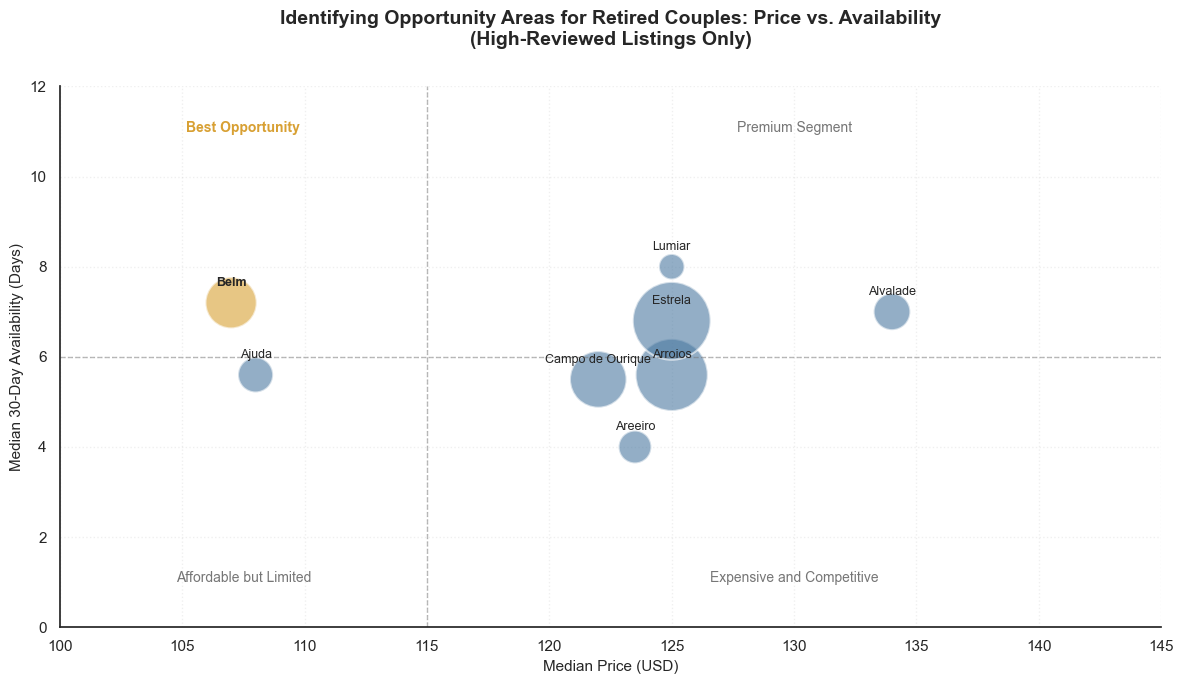

In [224]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Summary values from the neighbourhood groupby above
data = {
    'Neighborhood': ['Arroios', 'Estrela', 'Campo de Ourique', 'Belm', 'Ajuda', 'Alvalade', 'Areeiro', 'Lumiar'],
    'Median Price': [125.0, 125.0, 122.0, 107.0, 108.0, 134.0, 123.5, 125.0],
    'Count (n)': [135, 157, 83, 68, 32, 35, 28, 17],
    'Median Availability': [5.6, 6.8, 5.5, 7.2, 5.6, 7.0, 4.0, 8.0] 
}
df = pd.DataFrame(data)

# 2. Plot style
sns.set_theme(style="white") 
plt.figure(figsize=(12, 7))

plt.scatter(
    x=df['Median Price'], 
    y=df['Median Availability'], 
    s=df['Count (n)'] * 20, 
    c=['#D8A033' if x == 'Belm' else '#4B79A1' for x in df['Neighborhood']],
    alpha=0.6,
    edgecolors="white",
    linewidth=1.5
)

plt.xlim(100, 145)
plt.ylim(0, 12)

plt.axvline(x=115, color='#767676', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(y=6.0, color='#767676', linestyle='--', alpha=0.5, linewidth=1)

plt.text(107.5, 11, 'Best Opportunity', fontsize=10, color='#D8A033', fontweight='bold', ha='center')
plt.text(130.0, 11, 'Premium Segment', fontsize=10, color='#767676', ha='center')
plt.text(107.5, 1, 'Affordable but Limited', fontsize=10, color='#767676', ha='center')
plt.text(130.0, 1, 'Expensive and Competitive', fontsize=10, color='#767676', ha='center')

plt.title('Identifying Opportunity Areas for Retired Couples: Price vs. Availability\n(High-Reviewed Listings Only)', 
          fontsize=14, fontweight='bold', pad=30)
plt.xlabel('Median Price (USD)', fontsize=11)
plt.ylabel('Median 30-Day Availability (Days)', fontsize=11)

for i, txt in enumerate(df['Neighborhood']):
    plt.annotate(
        txt, 
        (df['Median Price'][i], df['Median Availability'][i]), 
        textcoords="offset points", 
        xytext=(0, 12), 
        ha='center', 
        fontsize=9,
        fontweight='bold' if txt == 'Belm' else 'normal'
    )

plt.grid(True, linestyle=':', alpha=0.3)
sns.despine()

plt.tight_layout()
plt.show()

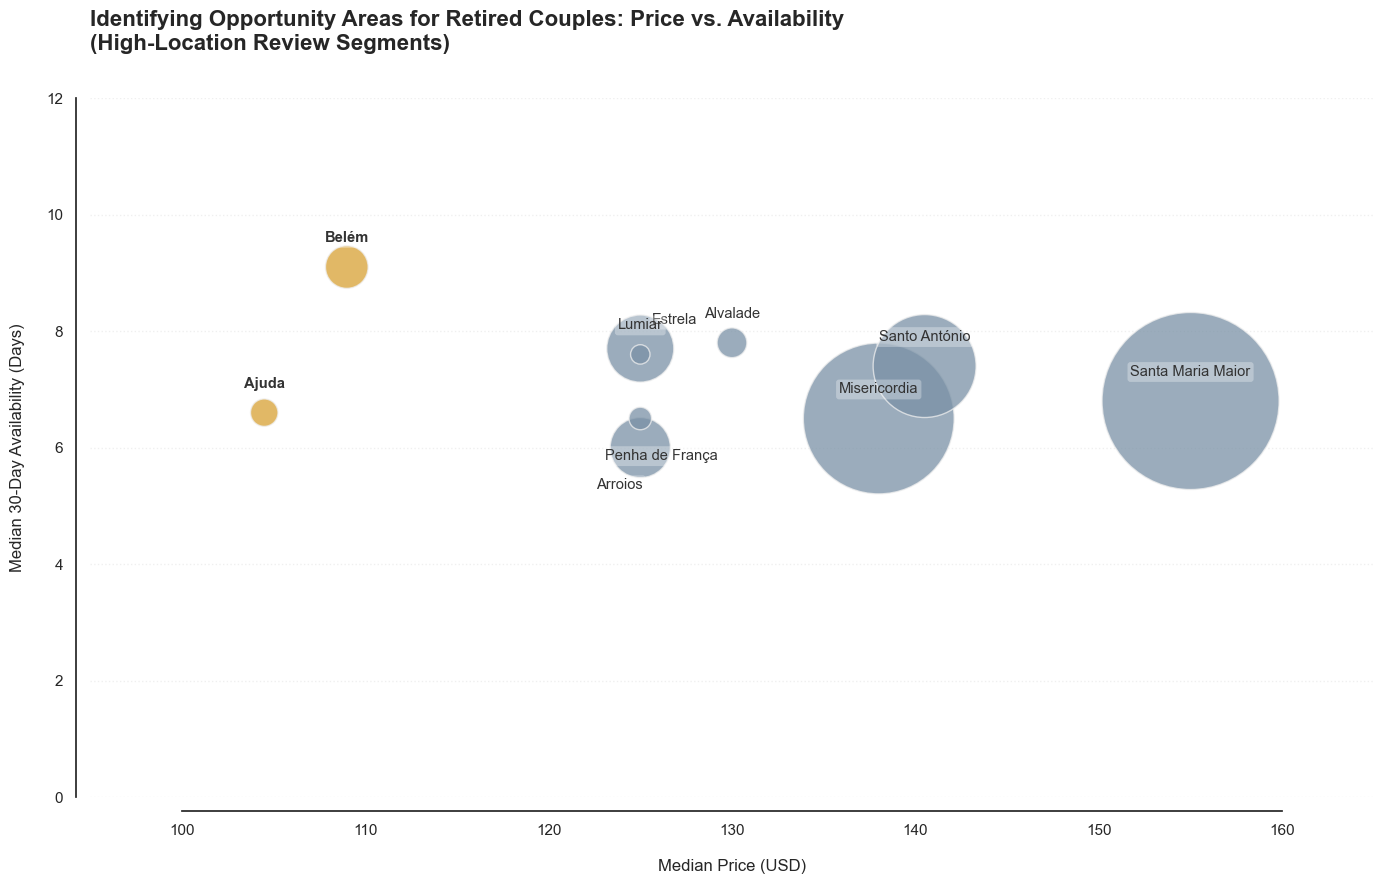

In [225]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Summary values from the neighbourhood groupby above
data = {
    'Neighborhood': ['Ajuda', 'Alvalade', 'Arroios', 'Belém', 'Estrela', 
                     'Lumiar', 'Misericordia', 'Santa Maria Maior', 'Santo António', 'Penha de França'],
    'Price': [104.5, 130.0, 125.0, 109.0, 125.0, 125.0, 138.0, 155.0, 140.5, 125.0],
    'Availability': [6.6, 7.8, 6.0, 9.1, 7.7, 7.6, 6.5, 6.8, 7.4, 6.5],
    'Count': [46, 54, 221, 111, 274, 23, 1387, 1912, 646, 31]
}
df = pd.DataFrame(data)

plt.figure(figsize=(14, 9))
sns.set_theme(style="white")

colors = ['#D8A033' if x in ['Belém', 'Ajuda'] else '#7A91A6' for x in df['Neighborhood']]

plt.scatter(
    x=df['Price'], 
    y=df['Availability'], 
    s=df['Count'] * 8.5,
    c=colors,
    alpha=0.75,
    edgecolors="
    linewidth=1.0
)

for i, txt in enumerate(df['Neighborhood']):
    x_off, y_off = 0, 18 
    
    if txt == 'Arroios': x_off, y_off = -15, -30 
    if txt == 'Penha de França': x_off, y_off = 15, -30
    if txt == 'Estrela': x_off = 25 
    
    plt.annotate(
        txt, 
        (df['Price'][i], df['Availability'][i]), 
        textcoords="offset points", 
        xytext=(x_off, y_off), 
        ha='center', 
        fontsize=10.5,
        fontweight='bold' if txt in ['Belém', 'Ajuda'] else 'normal',
        color='#333333',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.3, ec='none')
    )

plt.title('Identifying Opportunity Areas for Retired Couples: Price vs. Availability\n(High-Location Review Segments)', 
          fontsize=16, fontweight='bold', pad=35, loc='left')
plt.xlabel('Median Price (USD)', fontsize=12, labelpad=15)
plt.ylabel('Median 30-Day Availability (Days)', fontsize=12, labelpad=15)

plt.xlim(95, 165)
plt.ylim(0, 12)
plt.grid(axis='y', linestyle=':', alpha=0.3) 

sns.despine(offset=10, trim=True)

plt.tight_layout()
plt.show()

Analyse room type differences

In [226]:
high_review.groupby('room_type')[['price', 'availability_30']].median()

,price,availability_30
room_type,,
Entire home/apt,139.0,5.0
Hotel room,180.5,3.0
Private room,59.0,6.0


In [227]:
high_review.groupby('room_type')[['price', 'availability_30']].describe()

price                                                       \
                  count        mean          std    min    25%    50%    75%   
room_type                                                                      
Entire home/apt  3064.0  239.104765  1992.858281   28.0  110.0  139.0  199.0   
Hotel room         15.0  206.700000    56.809142  122.0  180.5  180.5  252.0   
Private room      469.0   85.686567    72.199287   26.0   55.0   59.0  100.0   

                         availability_30                                     \
                     max           count      mean       std  min  25%  50%   
room_type                                                                     
Entire home/apt  86733.0          3064.0  6.609661  6.615634  0.0  2.0  5.0   
Hotel room         327.0            15.0  6.066667  8.447034  0.0  0.0  3.0   
Private room      1080.0           469.0  8.313433  8.746297  0.0  1.0  6.0   

                             
                  75%   max  
room_type                    
Entire home/apt   9.0  30.0  
Hotel room        8.0  27.0  
Private room     13.0  30.0

Key finding: 
Entire homes/apartments make up the largest share of high-reviewed listings, but their 30-day availability is slightly lower than that of private rooms. At the same time, the median price of an entire home/apartment is more than twice that of a private room. This suggests that although private rooms may be somewhat easier to access at short notice, they may not provide the same level of privacy preferred by retired couples. Hotel rooms appear less informative in this comparison due to their very small sample size. Overall, these patterns suggest a possible market gap for affordable, private, and short-notice bookable accommodation for retired couples.

In [228]:
analysis_couple.groupby('room_type')[['price', 'availability_30']].describe()

price                                                      \
                   count        mean          std   min    25%    50%    75%   
room_type                                                                      
Entire home/apt  12112.0  194.611460  1105.110500  23.0   98.0  125.0  172.0   
Hotel room         118.0  206.500000   155.544659  47.0  152.0  180.5  180.5   
Private room      3067.0   80.758396   117.006163  18.0   49.0   57.0   72.0   

                         availability_30                                       \
                     max           count       mean        std  min  25%  50%   
room_type                                                                       
Entire home/apt  86733.0         12112.0   7.870459   7.723740  0.0  2.0  6.0   
Hotel room         850.0           118.0  10.398305  11.336455  0.0  0.0  4.0   
Private room      1421.0          3067.0   9.632214  10.039471  0.0  0.0  6.0   

                             
                  75%   max  
room_type                    
Entire home/apt  12.0  30.0  
Hotel room       23.0  30.0  
Private room     18.0  30.0

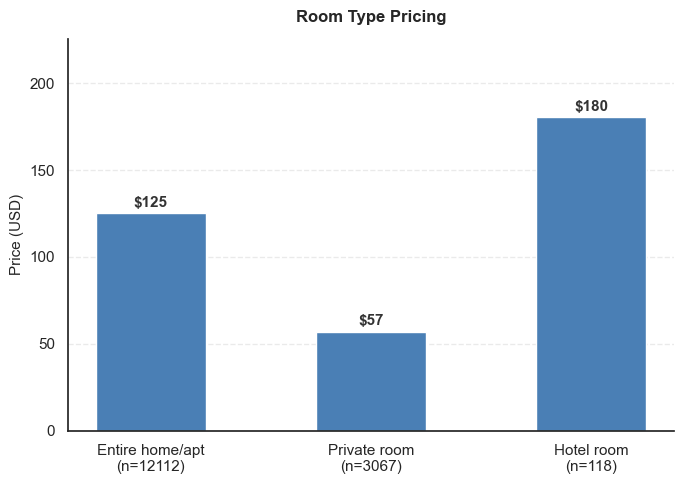

In [229]:
# Figure: Median Price by Room Type
import matplotlib.pyplot as plt
import numpy as np

room_types = ['Entire home/apt\n(n=12112)', 'Private room\n(n=3067)', 'Hotel room\n(n=118)']
price_median = [125.0, 57.0, 180.5]
x = np.arange(len(room_types))

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(x, price_median, width=0.5, color='#4a7fb5', edgecolor='white')

for bar, val in zip(bars, price_median):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f'${val:.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#333')

ax.set_xticks(x)
ax.set_xticklabels(room_types, fontsize=11)
ax.set_ylabel('Price (USD)', fontsize=11)
ax.set_title('Room Type Pricing',
             fontsize=12, fontweight='bold', pad=12)
ax.set_ylim(0, max(price_median) * 1.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('median_price.png', dpi=150, bbox_inches='tight')
plt.show()

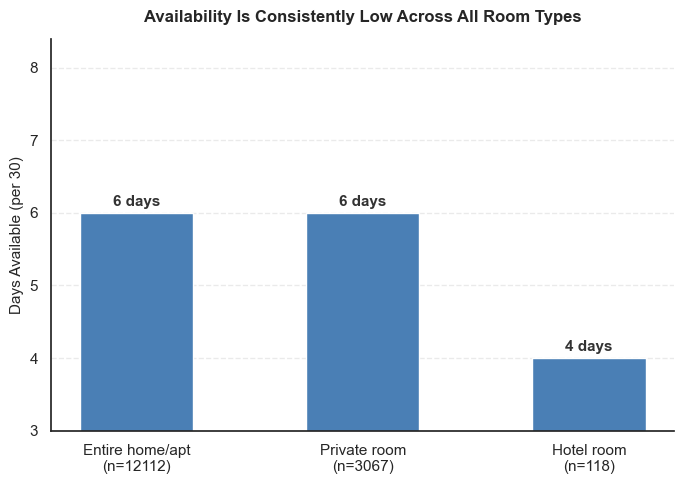

In [230]:
# Figure: Median Availability by Room Type
import matplotlib.pyplot as plt
import numpy as np

room_types = ['Entire home/apt\n(n=12112)', 'Private room\n(n=3067)', 'Hotel room\n(n=118)']
availability_median = [6.0, 6.0, 4.0]
x = np.arange(len(room_types))

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(x, availability_median, width=0.5, color='#4a7fb5', edgecolor='white')

for bar, val in zip(bars, availability_median):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{val:.0f} days', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#333')

ax.set_xticks(x)
ax.set_xticklabels(room_types, fontsize=11)
ax.set_ylabel('Days Available (per 30)', fontsize=11)
ax.set_title('Availability Is Consistently Low Across All Room Types',
             fontsize=12, fontweight='bold', pad=12)
ax.set_ylim(3, max(availability_median) * 1.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('median_availability.png', dpi=150, bbox_inches='tight')
plt.show()

In [231]:
analysis_couple[analysis_couple['first_review'].isna()].groupby('room_type')[['price', 'availability_30']].describe()

price                                                       \
                  count        mean          std    min    25%    50%    75%   
room_type                                                                      
Entire home/apt  1232.0  324.603084  1117.120056   35.0  120.0  134.0  189.0   
Hotel room         49.0  272.326531   207.703353  180.5  180.5  180.5  180.5   
Private room      446.0  150.840807   261.496702   22.0   57.0   57.0  108.0   

                        availability_30                                        \
                    max           count       mean        std  min  25%   50%   
room_type                                                                       
Entire home/apt  9999.0          1232.0   8.623377  10.692483  0.0  0.0   3.0   
Hotel room        850.0            49.0  14.102041  13.277871  0.0  0.0  18.0   
Private room     1380.0           446.0  12.125561  11.828832  0.0  0.0   9.0   

                             
                  75%   max  
room_type                    
Entire home/apt  17.0  30.0  
Hotel room       27.0  30.0  
Private room     24.0  30.0

In [232]:
analysis_couple.first_review.unique()

<StringArray>
['2014-09-02', '2014-04-24', '2012-05-22', '2011-01-05', '2010-07-24',
 '2011-06-29', '2011-10-12', '2011-07-18', '2011-12-13', '2018-08-14',
 ...
 '2025-08-26', '2025-09-20', '2025-09-04', '2025-09-17', '2025-09-09',
 '2025-08-30', '2025-09-22', '2025-09-19', '2025-09-13', '2025-09-23']
Length: 3676, dtype: str

In [233]:
analysis_couple.columns

Index(['id', 'price', 'room_type', 'accommodates', 'bathrooms', 'bedrooms',
       'beds', 'amenities', 'minimum_nights', 'maximum_nights',
       'has_availability', 'availability_30', 'availability_60',
       'availability_90', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
       'number_of_reviews_ly', 'estimated_occupancy_l365d',
       'estimated_revenue_l365d', 'first_review', 'last_review',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'reviews_per_month', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed'],
      dtype='str')

Kitchen Analysis

In [234]:
kitchen_analysis = analysis_couple.copy()

In [235]:
kitchen_analysis.amenities.unique()

<StringArray>
[                                                                                                                                                                                                                                                                                                                                                                                                                                   '["Microwave", "Cooking basics", "Dishes and silverware", "Mini fridge", "Host greets you", "Hot water", "Body soap", "Cleaning products", "Hangers", "Carbon monoxide alarm", "First aid kit", "Paid street parking off premises", "Ethernet connection", "Free street parking", "Stove", "Hair dryer", "Kitchen", "Paid parking on premises", "Long term stays allowed", "Oven", "River view", "Fire extinguisher", "Hot water kettle", "Shampoo", "Freezer", "TV with standard cable", "Essentials", "Shower gel", "Wifi", "Dining table", "Free washer \u2013 In unit", "Bed linen

In [236]:
kitchen_keywords = ['Cooking', 'Microwave', 'Dishes', 'Oven', 'kitchen', 'stove']
pattern = '|'. join(kitchen_keywords)
has_kitchen = kitchen_analysis[
    kitchen_analysis['amenities'].str.contains(pattern, case = False, na = False)
                               ]

# Kitchen flag
kitchen_analysis['has_kitchen'] = kitchen_analysis['amenities'].str.contains(
    pattern, case=False, na=False
)

print("properties with kitchen:", kitchen_analysis['has_kitchen'].sum())
print("total properties:", len(kitchen_analysis))

properties with kitchen: 14767
total properties: 15297


In [237]:
analysis_couple.groupby('room_type')[['price', 'availability_30']].describe()

price                                                      \
                   count        mean          std   min    25%    50%    75%   
room_type                                                                      
Entire home/apt  12112.0  194.611460  1105.110500  23.0   98.0  125.0  172.0   
Hotel room         118.0  206.500000   155.544659  47.0  152.0  180.5  180.5   
Private room      3067.0   80.758396   117.006163  18.0   49.0   57.0   72.0   

                         availability_30                                       \
                     max           count       mean        std  min  25%  50%   
room_type                                                                       
Entire home/apt  86733.0         12112.0   7.870459   7.723740  0.0  2.0  6.0   
Hotel room         850.0           118.0  10.398305  11.336455  0.0  0.0  4.0   
Private room      1421.0          3067.0   9.632214  10.039471  0.0  0.0  6.0   

                             
                  75%   max  
room_type                    
Entire home/apt  12.0  30.0  
Hotel room       23.0  30.0  
Private room     18.0  30.0

In [238]:
has_kitchen.groupby('room_type')[['price', 'availability_30']].describe()

price                                                     \
                   count        mean          std   min   25%    50%    75%   
room_type                                                                     
Entire home/apt  12049.0  194.904805  1107.965889  23.0  98.0  125.0  172.0   
Hotel room          45.0  139.311111    69.263109  47.0  77.0  145.0  180.5   
Private room      2673.0   74.597830   113.222528  18.0  48.0   57.0   67.0   

                         availability_30                                      \
                     max           count      mean        std  min  25%  50%   
room_type                                                                      
Entire home/apt  86733.0         12049.0  7.855424   7.707726  0.0  2.0  6.0   
Hotel room         407.0            45.0  9.511111   9.377493  0.0  3.0  5.0   
Private room      1380.0          2673.0  9.532735  10.062443  0.0  0.0  6.0   

                             
                  75%   max  
room_type                    
Entire home/apt  12.0  30.0  
Hotel room       21.0  26.0  
Private room     18.0  30.0

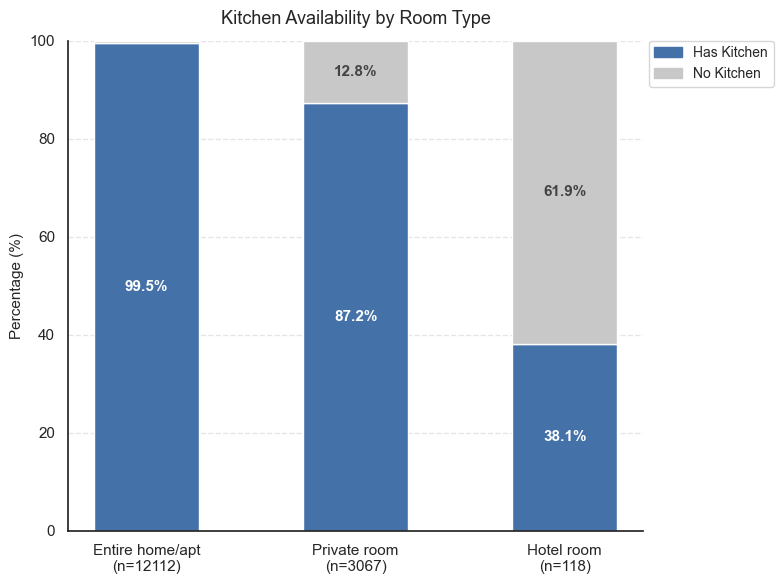

In [239]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

total   = {'Entire home/apt': 12112, 'Private room': 3067, 'Hotel room': 118}
kitchen = {'Entire home/apt': 12049, 'Private room': 2673, 'Hotel room': 45}

keys       = ['Entire home/apt', 'Private room', 'Hotel room']
room_types = ['Entire home/apt\n(n=12112)', 'Private room\n(n=3067)', 'Hotel room\n(n=118)']

has_k = [round(kitchen[k] / total[k] * 100, 1) for k in keys]
no_k  = [round(100 - v, 1) for v in has_k]

x     = np.arange(len(room_types))
width = 0.5

fig, ax = plt.subplots(figsize=(8, 6))
bars1 = ax.bar(x, has_k, width, color='#4472a8', label='Has Kitchen')
bars2 = ax.bar(x, no_k,  width, bottom=has_k,   color='#c8c8c8', label='No Kitchen')

for bar, val in zip(bars1, has_k):
    if val >= 3:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                f'{val}%', ha='center', va='center', color='white', fontsize=11, fontweight='bold')

for bar, val, base in zip(bars2, no_k, has_k):
    if val >= 3:
        ax.text(bar.get_x() + bar.get_width()/2, base + val/2,
                f'{val}%', ha='center', va='center', color='#444', fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(room_types, fontsize=11)
ax.set_ylabel('Percentage (%)', fontsize=11)
ax.set_ylim(0, 100)
ax.set_title('Kitchen Availability by Room Type', fontsize=13, pad=12)

ax.legend(
    handles=[mpatches.Patch(color='#4472a8', label='Has Kitchen'),
             mpatches.Patch(color='#c8c8c8', label='No Kitchen')],
    loc='upper left',
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    fontsize=10
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('kitchen_availability_all.png', dpi=150, bbox_inches='tight')
plt.show()

Minimun stay

In [240]:
has_kitchen.groupby('room_type')['minimum_nights'].describe()

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,12049.0,5.623454,17.460187,1.0,1.0,2.0,3.0,730.0
Hotel room,45.0,1.422222,0.656744,1.0,1.0,1.0,2.0,4.0
Private room,2673.0,2.515900,6.954126,1.0,1.0,1.0,2.0,180.0


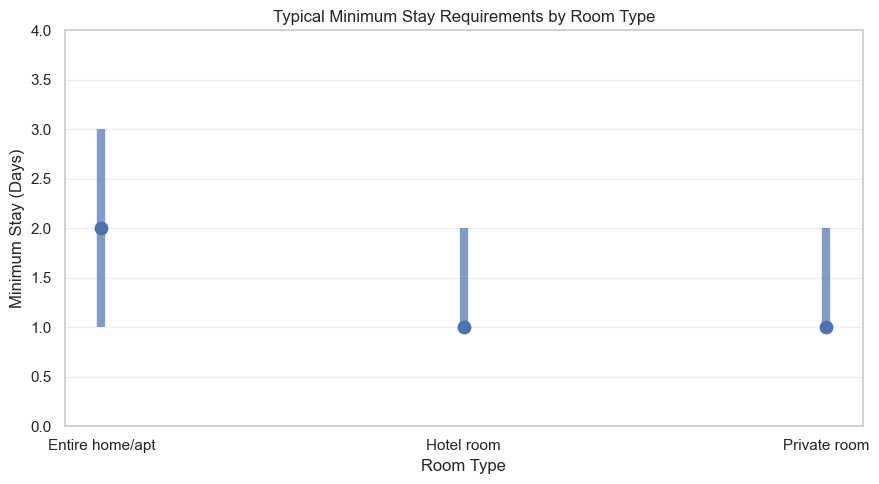

In [259]:
import matplotlib.pyplot as plt
import pandas as pd

# Summary statistics
summary = has_kitchen.groupby('room_type')['minimum_nights'].describe()

room_order = ['Entire home/apt', 'Hotel room', 'Private room']
summary = summary.loc[room_order]

x = range(1, len(room_order) + 1)
q1 = summary['25%']
median = summary['50%']
q3 = summary['75%']

fig, ax = plt.subplots(figsize=(9, 5))

# IQR lines
ax.vlines(x, q1, q3, linewidth=6, alpha=0.7)

# Median points
ax.scatter(x, median, s=80, zorder=3)

ax.set_xticks(list(x))
ax.set_xticklabels(room_order)
ax.set_title('Typical Minimum Stay Requirements by Room Type')
ax.set_xlabel('Room Type')
ax.set_ylabel('Minimum Stay (Days)')

ax.grid(axis='y', linestyle='-', alpha=0.3)
ax.grid(axis='x', visible=False)
ax.set_ylim(0, 4)

plt.tight_layout()
plt.show()

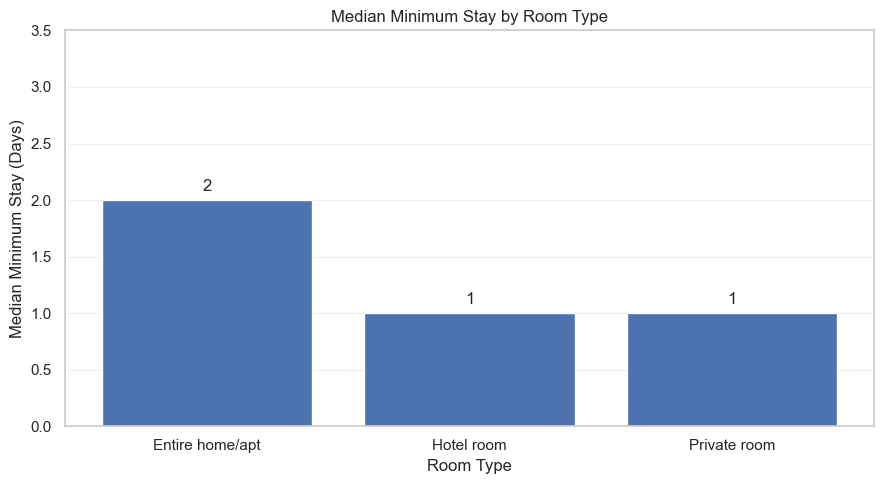

In [260]:
import matplotlib.pyplot as plt
import pandas as pd

median_stay = has_kitchen.groupby('room_type')['minimum_nights'].median()

room_order = ['Entire home/apt', 'Hotel room', 'Private room']
median_stay = median_stay.loc[room_order]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(median_stay.index, median_stay.values)

ax.set_title('Median Minimum Stay by Room Type')
ax.set_xlabel('Room Type')
ax.set_ylabel('Median Minimum Stay (Days)')

# Value labels
for bar in bars:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.05,
        f'{value:.0f}',
        ha='center',
        va='bottom'
    )

ax.grid(axis='y', linestyle='-', alpha=0.3)
ax.grid(axis='x', visible=False)
ax.set_ylim(0, 3.5)

plt.tight_layout()
plt.show()

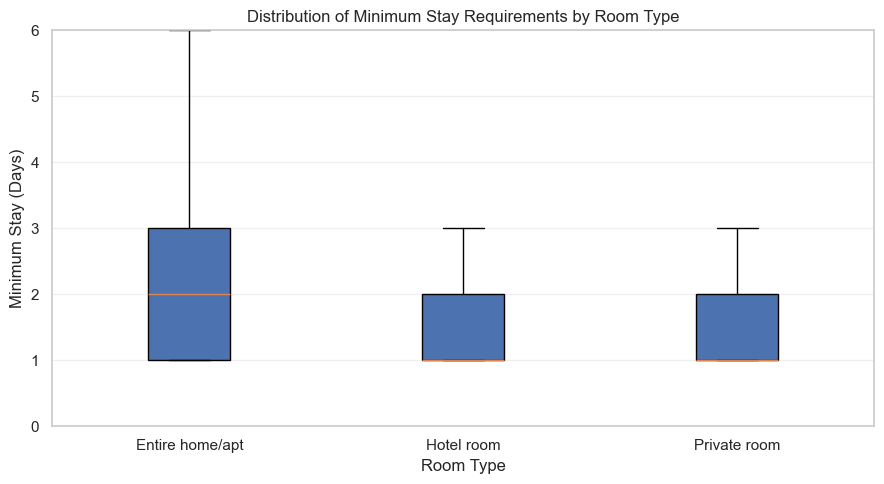

In [258]:
import matplotlib.pyplot as plt
import pandas as pd

room_order = ['Entire home/apt', 'Hotel room', 'Private room']
plot_df = has_kitchen[has_kitchen['room_type'].isin(room_order)].copy()

plot_df['minimum_nights'] = pd.to_numeric(plot_df['minimum_nights'], errors='coerce')
plot_df = plot_df.dropna(subset=['minimum_nights'])

data_to_plot = [
    plot_df.loc[plot_df['room_type'] == room, 'minimum_nights']
    for room in room_order
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    data_to_plot,
    tick_labels=room_order,
    patch_artist=True,
    showfliers=False
)

ax.grid(axis='y', linestyle='-', alpha=0.3)
ax.grid(axis='x', visible=False)

ax.set_title('Distribution of Minimum Stay Requirements by Room Type')
ax.set_xlabel('Room Type')
ax.set_ylabel('Minimum Stay (Days)')
ax.set_ylim(0, 6)

plt.tight_layout()
plt.show()

Reviews

In [242]:
target_listings = kitchen_analysis[
    (kitchen_analysis['room_type'] == 'Entire home/apt') &
    (kitchen_analysis['has_kitchen'] == True)
].copy()

print("target listings:", len(target_listings))

target listings: 12049


In [243]:
review_cols = [
    'number_of_reviews',
    'availability_30',
    'estimated_occupancy_l365d',
    'reviews_per_month',
    'price'
]

print(target_listings[review_cols].isna().sum())

number_of_reviews               0
availability_30                 0
estimated_occupancy_l365d       0
reviews_per_month            1218
price                           0
dtype: int64


In [244]:
target_listings['review_binary'] = np.where(
    target_listings['number_of_reviews'] == 0,
    'No reviews',
    'Reviewed'
)

print(target_listings['review_binary'].value_counts())

review_binary
Reviewed      10831
No reviews     1218
Name: count, dtype: int64


In [245]:
bins = [-1, 0, 5, 20, target_listings['number_of_reviews'].max()]
labels = ['0 reviews', '1-5 reviews', '6-20 reviews', '20+ reviews']

target_listings['review_group'] = pd.cut(
    target_listings['number_of_reviews'],
    bins=bins,
    labels=labels
)

print(target_listings['review_group'].value_counts(dropna=False))

review_group
20+ reviews     7475
1-5 reviews     1689
6-20 reviews    1667
0 reviews       1218
Name: count, dtype: int64


In [246]:
summary_table = target_listings.groupby('review_group').agg(
    listing_count=('id', 'count'),
    median_price=('price', 'median'),
    median_availability_30=('availability_30', 'median'),
    median_occupancy=('estimated_occupancy_l365d', 'median'),
    mean_reviews_per_month=('reviews_per_month', 'mean'),
    median_reviews_l30d=('number_of_reviews_l30d', 'median')
).reset_index()

print(summary_table)

   review_group  listing_count  median_price  median_availability_30  \
0     0 reviews           1218         134.5                     3.0   
1   1-5 reviews           1689         125.0                     5.0   
2  6-20 reviews           1667         125.0                     7.0   
3   20+ reviews           7475         125.0                     6.0   

   median_occupancy  mean_reviews_per_month  median_reviews_l30d  
0               0.0                     NaN                  0.0  
1              12.0                0.693085                  0.0  
2              42.0                1.285183                  0.0  
3             162.0                2.309039                  2.0  


In [247]:
print(summary_table[['review_group', 'median_availability_30', 'median_occupancy', 'median_price']])

   review_group  median_availability_30  median_occupancy  median_price
0     0 reviews                     3.0               0.0         134.5
1   1-5 reviews                     5.0              12.0         125.0
2  6-20 reviews                     7.0              42.0         125.0
3   20+ reviews                     6.0             162.0         125.0


In [248]:
target_listings.groupby('review_group')['has_availability'].value_counts(dropna=False)

review_group  has_availability
0 reviews     t                   1169
              NaN                   49
1-5 reviews   t                   1648
              NaN                   41
6-20 reviews  t                   1627
              NaN                   40
20+ reviews   t                   7416
              NaN                   59
Name: count, dtype: int64

In [249]:
availability_summary = target_listings.groupby('review_group').agg(
    listing_count=('id', 'count'),
    median_availability_30=('availability_30', 'median'),
    median_availability_60=('availability_60', 'median'),
    median_availability_90=('availability_90', 'median'),
    median_availability_365=('availability_365', 'median'),
    median_occupancy=('estimated_occupancy_l365d', 'median'),
    median_price=('price', 'median')
).reset_index()

print(availability_summary)

   review_group  listing_count  median_availability_30  \
0     0 reviews           1218                     3.0   
1   1-5 reviews           1689                     5.0   
2  6-20 reviews           1667                     7.0   
3   20+ reviews           7475                     6.0   

   median_availability_60  median_availability_90  median_availability_365  \
0                    19.5                    46.0                    268.0   
1                    22.0                    49.0                    268.0   
2                    27.0                    54.0                    285.0   
3                    24.0                    51.0                    280.0   

   median_occupancy  median_price  
0               0.0         134.5  
1              12.0         125.0  
2              42.0         125.0  
3             162.0         125.0  


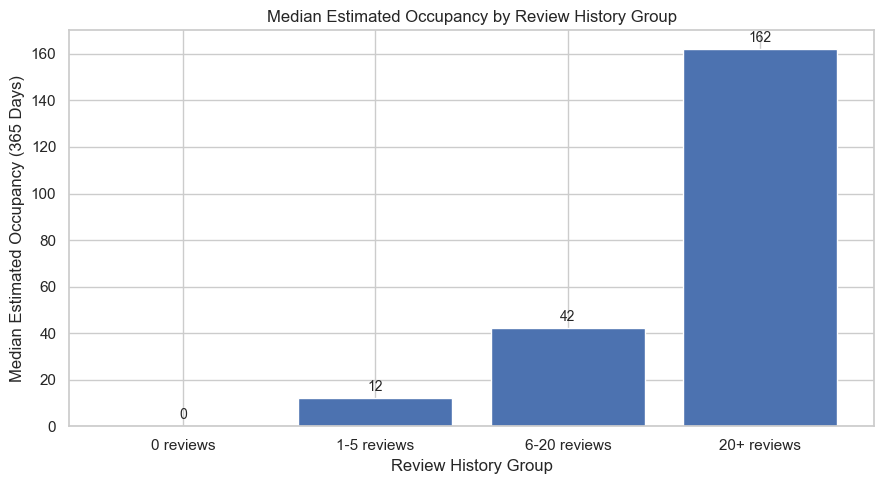

In [253]:
import matplotlib.pyplot as plt
import pandas as pd

order = ['0 reviews', '1-5 reviews', '6-20 reviews', '20+ reviews']

plot_data = summary_table[['review_group', 'median_occupancy']].copy()
plot_data['review_group'] = pd.Categorical(
    plot_data['review_group'],
    categories=order,
    ordered=True
)
plot_data = plot_data.sort_values('review_group')

plt.figure(figsize=(9, 5))
bars = plt.bar(plot_data['review_group'].astype(str), plot_data['median_occupancy'])

plt.title('Median Estimated Occupancy by Review History Group')
plt.xlabel('Review History Group')
plt.ylabel('Median Estimated Occupancy (365 Days)')

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f'{int(value)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()